# A passive notch filter and component tolerance

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/04-notch-filter/notebook.ipynb)

## Goal
An ideal voltage source drives series $R$, $L$ and $C$. Measure the combined voltage $y=v_L+v_C$. Use $L=10\,\mathrm{mH}$, $C=100\,\mu\mathrm{F}$ and $R=10\,\Omega$. Derive the notch transfer, compare it with the capacitor-voltage response, and evaluate the effect of a $\pm10\%$ capacitance tolerance. Assume ideal components and an unloaded measurement.

**Evidence:** every parameter and dataset is synthetic and was chosen for this original teaching scenario.

## Start from the physical system

![Physical system](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/04-notch-filter/figures/physical-system.png)

A source excites the series RLC network; an ideal differential probe spans the combined inductor and capacitor. Measuring only the capacitor would produce a different transfer function. Wire placement is schematic.

[Five integrated practice problems](https://github.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/blob/main/laboratories/04-notch-filter/exercises.pdf) accompany this model.

## Read the system diagram

![System diagram](https://raw.githubusercontent.com/fobos123deimos/Undergraduate-Course-Control-of-Dynamical-Systems/main/laboratories/04-notch-filter/figures/system-diagram.png)

Series RLC network with output measured across L and C together. The output probe spans those two components, not the whole source.

The diagram is original TikZ artwork; the numerical records below are synthetic.

## Setup
Run the optional installation cell if packages are missing. No private data, supplied PDFs or external model files are required.

In [ ]:
%pip -q install numpy scipy matplotlib control

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, least_squares
plt.ioff()
plt.rcParams.update({'figure.figsize': (9,4.5), 'font.size': 10, 'axes.grid': True, 'grid.alpha': .25})


## Derive the model
### Voltage division
The impedances are $Z_R=R$, $Z_L=sL$ and $Z_C=1/(sC)$. Measuring across the combined LC section gives

$$
G_n(s)=\frac{sL+1/(sC)}{R+sL+1/(sC)}=\frac{LCs^2+1}{LCs^2+RCs+1}.
$$

Measuring across C alone instead gives $G_C(s)=1/(LCs^2+RCs+1)$. Both share poles, but their zeros and frequency responses differ.
### Nominal design
Here $LC=10^{-6}$ s$^2$, $RC=10^{-3}$ s, $\omega_0=1/\sqrt{LC}=1000$ rad/s and $\zeta=(R/2)\sqrt{C/L}=0.5$. The notch has zeros at $\pm j1000$ and stable poles $-500\pm j866.0254$. Its DC and high-frequency gains are one.
### Tolerance analysis
At ideal resonance, the inductor and capacitor voltages cancel in their sum. A capacitance factor $a$ moves the notch to $\omega_0/\sqrt a$; a 10 percent tolerance is not a symmetric 10 percent frequency change. The first-order sensitivity is $\delta\omega_0/\omega_0\simeq-\delta C/(2C)$.
### Physical interpretation
A zero in the measured sum does not mean zero branch current or zero energy in the individual elements. Resistance in the inductor, source impedance and output loading reduce notch depth and alter the ideal transfer function. The logarithmic plot is clipped only for display at very small magnitudes.

## Compute and check
The first lines declare the scenario parameters. Follow the model construction, run the numerical experiment, and inspect the assertions and printed metrics.

In [2]:
inductance, capacitance, resistance = .01,100e-6,10.
angular=np.logspace(1,5,1600)
curves=[]
for factor in [.9,1.,1.1]:
    c=capacitance*factor
    model=ct.tf([inductance*c,0,1],[inductance*c,resistance*c,1])
    notch=1/np.sqrt(inductance*c)
    assert abs(ct.evalfr(model,1j*notch))<1e-12
    assert np.all(np.real(ct.poles(model))<0)
    response=np.array([abs(ct.evalfr(model,1j*w)) for w in angular])
    curves.append((factor,response))
    print(f'C factor={factor:.2f}: notch={notch:.6f} rad/s ({notch/(2*np.pi):.6f} Hz)')
capacitor=ct.tf([1],[inductance*capacitance,resistance*capacitance,1])
cap_response=np.array([abs(ct.evalfr(capacitor,1j*w)) for w in angular])


C factor=0.90: notch=1054.092553 rad/s (167.764040 Hz)


C factor=1.00: notch=1000.000000 rad/s (159.154943 Hz)


C factor=1.10: notch=953.462589 rad/s (151.748284 Hz)


## Plot the evidence
The figure below displays the computed experiment. Axis units and legends distinguish the model variants; the curves are simulations.

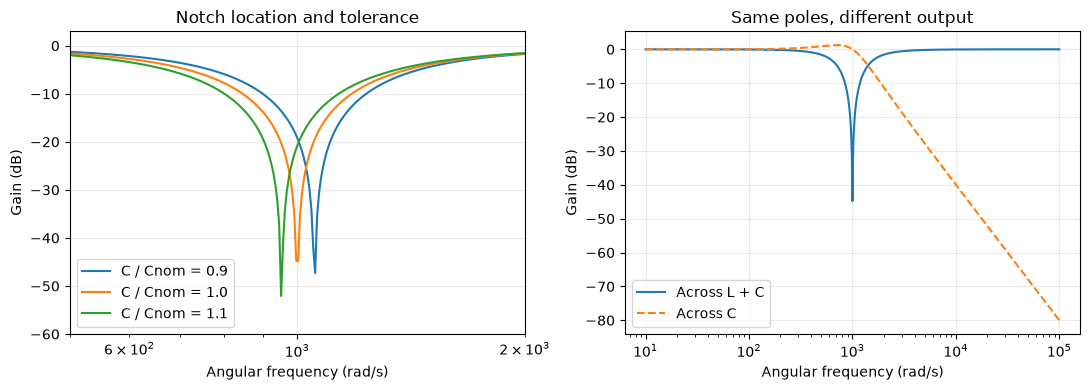

In [3]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
for factor,response in curves: axes[0].semilogx(angular,20*np.log10(np.maximum(response,1e-8)),label=f'C / Cnom = {factor:.1f}')
axes[0].set(xlabel='Angular frequency (rad/s)',ylabel='Gain (dB)',title='Notch location and tolerance',xlim=(500,2000),ylim=(-60,3)); axes[0].legend()
axes[1].semilogx(angular,20*np.log10(np.maximum(curves[1][1],1e-8)),label='Across L + C')
axes[1].semilogx(angular,20*np.log10(cap_response),'--',label='Across C')
axes[1].set(xlabel='Angular frequency (rad/s)',ylabel='Gain (dB)',title='Same poles, different output'); axes[1].legend()
fig.tight_layout()

plt.show()

## Interpret and extend
Output selection changes zeros even when the physical circuit is unchanged. An ideal notch is sensitive to component tolerance and omitted losses.

Change one parameter at a time, predict the direction of its effect from the equations, and rerun all cells. Explain any discrepancy before accepting a revised conclusion.

## References
- [APMonitor Dynamics and Control](https://apmonitor.com/pdc/)
- [Feedback Systems, open textbook](https://fbsbook.org/)
- [Python Control documentation](https://python-control.readthedocs.io/en/0.10.2/)
- [Worked PDF report](report.pdf)